# Imports

In [1]:
from utils import *

import pandas as pd
import numpy as np
from scipy.stats import norm, gaussian_kde
import matplotlib.pyplot as plt
from matplotlib.patches import Patch, Rectangle
from matplotlib.lines import Line2D
from matplotlib.gridspec import GridSpec


# Setup

In [2]:
##############################
# Setup Parameters
##############################

# path to cleaned dataset
clean_path = r'../data/mnz_cleaned.csv'

# list of structural tectonic zones west to east
structural_zones = ['MDHSZ', 'GS', 'CBSZ', 'CMZI']

# type of grouping
group_type = 'manual'

# path for output figure
output_dir = r'../results'


##### read into df...
df = pd.read_csv(clean_path)
df.sort_values('error', inplace=True)
df.reset_index(inplace=True)

df.head()

,level_0,index,sample,zone,mnz,texture,texture_chem,n,age,error,...,Er2O3,Tm2O3,Yb2O3,SO3,PbO,percent,lree,HREE,garnet,cordierite
0,0,8,EB14-001,CMZI,m28,overgrowth,Y depleted overgrowth,6.0,348.85,0.683097,...,0.034439,0.069372,0.009740,0.018835,0.096939,0.195814,59.804756,1.359903,1,0
1,2,176,P14-005A-5B,CBSZ,m20,core,Y depleted core,NaN,356.00,0.784962,...,0.014718,0.009812,0.009812,0.020605,0.079477,0.220495,61.972776,1.588568,1,0
2,1,111,P14-003-2B,MDHSZ,m50,core,Th enriched core,5.0,307.14,0.789124,...,0.009937,0.019969,0.009937,0.018184,0.132687,0.256926,57.520514,0.670830,1,0
3,3,114,M1605-2-L3,MDHSZ,m4,rim,Y depleted rim,5.0,298.70,1.346540,...,0.009748,0.009748,0.009748,0.016339,0.082968,0.450800,61.526147,1.376610,1,0
4,4,31,WA14-002,CMZI,m22,rim,Y depleted rim,5.0,353.24,1.408622,...,0.009641,0.060215,0.009641,0.014777,0.085454,0.398772,60.699177,1.389823,1,1


# Age Plots

## All Age Compilation

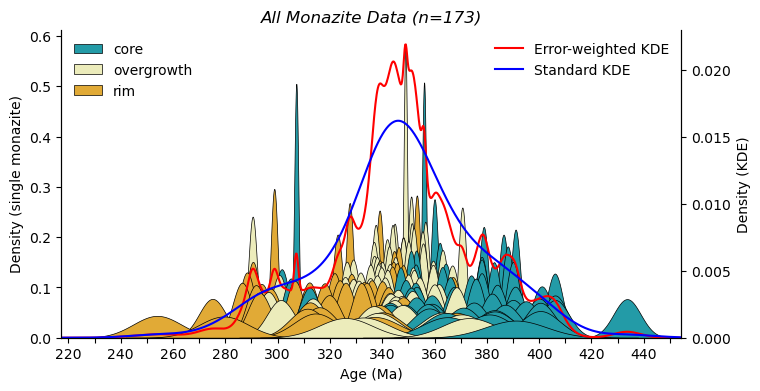

In [3]:
###################################
# Distributions of Ages (All Data)
###################################

fig, ax = plt.subplots(nrows=1, ncols=1, figsize=(8,4))


for idx, row in df.iterrows():
    mean = row['age']
    error = row['error']
    tex = row['texture']
    age_range = np.linspace(mean - 4 * error, mean + 4 * error, 100)
    density = norm.pdf(age_range, mean, error)
    ax.fill_between(age_range, density, alpha=1, color=texture_colors.get(tex), linewidth=0.5, edgecolor='k')

    if mean == df['age'].min():
        xmin = age_range.min()
    if mean == df['age'].max():
        xmax = age_range.max()


##### plot KDEs...
ages = df['age'].to_numpy()
errors = df['error'].to_numpy()
t = np.linspace(xmin, xmax, 1000)

# error-weighted KDE...
density_err = np.zeros_like(t)
for age, err in zip(ages, errors):
    density_err += np.exp(-(t-age)**2 / (2*err**2)) / (np.sqrt(2*np.pi)*err)
density_err /= len(ages)

# standard KDE...
kde = gaussian_kde(ages)
density_std = kde(t)

# plot KDEs...
ax2 = ax.twinx()
ax2.plot(t, density_err, color='red', label='Error-weighted KDE')
ax2.plot(t, density_std, color='blue', label='Standard KDE')


##### legend...
ax1_patches = []
for k,v in texture_colors.items():
    ax1_patches.append(Patch(facecolor=v, edgecolor='k', linewidth=0.5, label=k))
ax.legend(ax1_patches, [lab.get_label() for lab in ax1_patches], loc='upper left', bbox_to_anchor=(0,1), frameon=False)
ax2.legend(loc='upper right', bbox_to_anchor=(1,1), frameon=False)


##### figure styling...
ax.set_xlim(xmin, xmax)
ax.set_xticks(np.arange(220, 451, 10))
ax.set_xticklabels([str(i) if i%20 == 0 else '' for i in np.arange(220, 451, 10)])
ax.set_xlabel('Age (Ma)')
ax.set_ylim(0)
ax2.set_ylim(0)

ax.set_ylabel('Density (single monazite)')
ax2.set_ylabel('Density (KDE)')

ax.set_title(f"All Monazite Data (n={len(df)})", style='italic')
ax.spines['top'].set_visible(False)
ax2.spines['top'].set_visible(False)

# plt.savefig('all_ages.png', bbox_inches="tight", pad_inches=0, dpi=300)
plt.show()

## Multi-panel Age by Zone

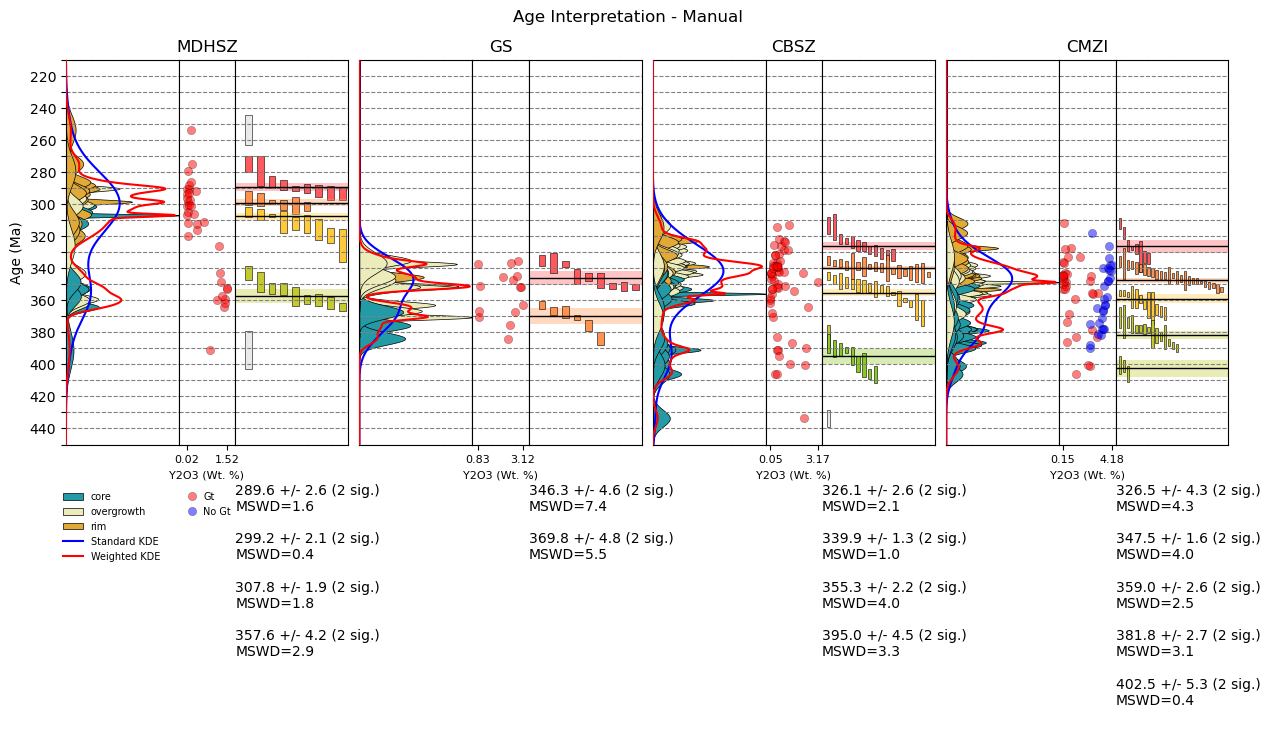

In [16]:
#################################################################
# Plot Multi-panel Age/Geology by Structural Zone - Manual Method
#################################################################


##### Setup figure...
# figure has 1 row + 15 columns (zone + spacer + zone + spacer + zone + spacer + zone)
# each structural zone has three panels: (1) individual sample Gaussian curves (+/- KDEs); (2) additional information; (3) Age Interpretation
fig = plt.figure(figsize=(15, 5))
width_ratios = [1.0, 0.5, 1.0, 0.1, 1.0, 0.5, 1.0, 0.1, 1.0, 0.5, 1.0, 0.1, 1.0, 0.5, 1.0]
gs = GridSpec(nrows=1, ncols=15, figure=fig, wspace=0, width_ratios=width_ratios)

# define axes - left triplet (A), spacer (hidden), right triplet (B)...
axA_1 = fig.add_subplot(gs[0, 0])
axA_2 = fig.add_subplot(gs[0, 1], sharey=axA_1)
axA_3 = fig.add_subplot(gs[0, 2], sharey=axA_1)
ax_sp1 = fig.add_subplot(gs[0, 3])                 # spacer
axB_1 = fig.add_subplot(gs[0, 4], sharey=axA_1)
axB_2 = fig.add_subplot(gs[0, 5], sharey=axA_1)
axB_3 = fig.add_subplot(gs[0, 6], sharey=axA_1)
ax_sp2 = fig.add_subplot(gs[0, 7])                 # spacer
axC_1 = fig.add_subplot(gs[0, 8], sharey=axA_1)
axC_2 = fig.add_subplot(gs[0, 9], sharey=axA_1)
axC_3 = fig.add_subplot(gs[0, 10], sharey=axA_1)
ax_sp3 = fig.add_subplot(gs[0, 11])                 # spacer
axD_1 = fig.add_subplot(gs[0, 12], sharey=axA_1)
axD_2 = fig.add_subplot(gs[0, 13], sharey=axA_1)
axD_3 = fig.add_subplot(gs[0, 14], sharey=axA_1)

# hide spacer axes...
ax_sp1.axis("off")
ax_sp2.axis("off")
ax_sp3.axis("off")




##### plot panels...
# iterate through structural zones...
for idx, zone in enumerate(structural_zones):

    # extract subset df
    df_subset = df.loc[df['zone']==zone].copy()


    ##### MDHSZ...
    if idx==0:

        # plot individual sample gaussian curves
        plot_samples_panel(df_subset, axA_1, 'texture', texture_colors, label_bool=True, y_label='Age (Ma)')

        # plot KDE curves on top of sample curves...
        axA_1B = axA_1.twiny()
        plot_kde_panel(df_subset, axA_1B)

        # plot Y2O3 weight percent
        plot_yttrium_panel(df_subset, axA_2, 'Y2O3', 'garnet')

        # plot age interpretations...
        mask0 = df_subset['age'] < 265
        mask1 = (df_subset['age'] >= 265) & (df_subset['age'] < 295)
        mask2 = (df_subset['age'] >= 295) & (df_subset['age'] < 305)
        mask3 = (df_subset['age'] >= 305) & (df_subset['age'] < 330)
        mask4 = (df_subset['age'] >= 330) & (df_subset['age'] < 370)
        mask5 = df_subset['age'] >= 370

        group0 = df_subset.loc[mask0]
        group1 = df_subset.loc[mask1]
        group2 = df_subset.loc[mask2]
        group3 = df_subset.loc[mask3]
        group4 = df_subset.loc[mask4]
        group5 = df_subset.loc[mask5]

        # plot each group individually
        plot_ageinterp_panel(group0, axA_3, -1, age_group_colors, bar_width, gap, ci='2sigma')
        plot_ageinterp_panel(group1, axA_3, 0, age_group_colors, bar_width, gap, ci='2sigma')
        plot_ageinterp_panel(group2, axA_3, 1, age_group_colors, bar_width, gap, ci='2sigma')
        plot_ageinterp_panel(group3, axA_3, 2, age_group_colors, bar_width, gap, ci='2sigma')
        plot_ageinterp_panel(group4, axA_3, 3, age_group_colors, bar_width, gap, ci='2sigma')
        plot_ageinterp_panel(group5, axA_3, -1, age_group_colors, bar_width, gap, ci='2sigma')

        # clean up axes... 
        axA_2.set_title(zone, loc='center')
        axA_3.set_xlim(0, max(len(group0), len(group1)) * (bar_width + gap + 0.05))

        # plot age group information below plot...
        label = ''
        for g in [group0, group1, group2, group3, group4, group5]:
            ages = g['age'].to_numpy()
            errors = g['error'].to_numpy()
            stats = cluster_stats(ages, errors, ci='2sigma')
            if stats['n'] >= 3:
                label += f"{round(stats['mean'],1)} +/- {round(stats['halfwidth'],1)} (2 sig.)\nMSWD={round(stats['mswd'], 1)}"
                label += '\n\n'
        axA_3.text(0, -0.1, label, transform=axA_3.transAxes, fontsize=10, ha='left', va='top')


    ##### GS...
    elif idx==1:
        plot_samples_panel(df_subset, axB_1, 'texture', texture_colors, label_bool=False, y_label='Age (Ma)')
        axB_1B = axB_1.twiny()
        plot_kde_panel(df_subset, axB_1B)
        plot_yttrium_panel(df_subset, axB_2, 'Y2O3', 'garnet')

        group0_mask = df_subset['age'] < 360
        group0 = df_subset.loc[group0_mask].copy()
        group1 = df_subset.loc[~group0_mask].copy()
        plot_ageinterp_panel(group0, axB_3, 0, age_group_colors, bar_width, gap, ci='2sigma')
        plot_ageinterp_panel(group1, axB_3, 1, age_group_colors, bar_width, gap, ci='2sigma')

        axB_2.set_title(zone, loc='center')
        axB_3.set_xlim(0, max(len(group0), len(group1)) * (bar_width + gap + 0.05))

        label = ''
        for g in [group0, group1]:
            ages = g['age'].to_numpy()
            errors = g['error'].to_numpy()
            stats = cluster_stats(ages, errors, ci='2sigma')
            label += f"{round(stats['mean'],1)} +/- {round(stats['halfwidth'],1)} (2 sig.)\nMSWD={round(stats['mswd'], 1)}"
            label += '\n\n'
        axB_3.text(0, -0.1, label, transform=axB_3.transAxes, fontsize=10, ha='left', va='top')

        
    ##### CBSZ...
    elif idx==2:
        plot_samples_panel(df_subset, axC_1, 'texture', texture_colors, label_bool=False, y_label='Age (Ma)')
        axC_1B = axC_1.twiny()
        plot_kde_panel(df_subset, axC_1B)
        plot_yttrium_panel(df_subset, axC_2, 'Y2O3', 'garnet')

        mask0 = df_subset['age'] < 335
        mask1 = (df_subset['age'] >= 335) & (df_subset['age'] < 345)
        mask2 = (df_subset['age'] >= 345) & (df_subset['age'] < 370)
        mask3 = (df_subset['age'] >= 375) & (df_subset['age'] < 385)
        mask4 = (df_subset['age'] >= 385) & (df_subset['age'] < 420)
        mask5 = df_subset['age'] >= 420

        group0 = df_subset.loc[mask0]
        group1 = df_subset.loc[mask1]
        group2 = df_subset.loc[mask2]
        group3 = df_subset.loc[mask3]
        group4 = df_subset.loc[mask4]
        group5 = df_subset.loc[mask5]

        plot_ageinterp_panel(group0, axC_3, 0, age_group_colors, bar_width, gap, ci='2sigma')
        plot_ageinterp_panel(group1, axC_3, 1, age_group_colors, bar_width, gap, ci='2sigma')
        plot_ageinterp_panel(group2, axC_3, 2, age_group_colors, bar_width, gap, ci='2sigma')
        plot_ageinterp_panel(group3, axC_3, 3, age_group_colors, bar_width, gap, ci='2sigma')
        plot_ageinterp_panel(group4, axC_3, 4, age_group_colors, bar_width, gap, ci='2sigma')
        plot_ageinterp_panel(group5, axC_3, -1, age_group_colors, bar_width, gap, ci='2sigma')


        axC_2.set_title(zone, loc='center')
        axC_3.set_xlim(0, max(len(group0), len(group1), len(group2), len(group3)) * (bar_width + gap + 0.05))

        label = ''
        for g in [group0, group1, group2, group3, group4, group5]:
            ages = g['age'].to_numpy()
            errors = g['error'].to_numpy()
            stats = cluster_stats(ages, errors, ci='2sigma')
            if stats['n'] >= 3:
                label += f"{round(stats['mean'],1)} +/- {round(stats['halfwidth'],1)} (2 sig.)\nMSWD={round(stats['mswd'], 1)}"
                label += '\n\n'
        axC_3.text(0, -0.1, label, transform=axC_3.transAxes, fontsize=10, ha='left', va='top')


    ##### CMZI...
    elif idx==3:
        plot_samples_panel(df_subset, axD_1, 'texture', texture_colors, label_bool=False, y_label='Age (Ma)')
        axD_1B = axD_1.twiny()
        plot_kde_panel(df_subset, axD_1B)
        plot_yttrium_panel(df_subset, axD_2, 'Y2O3', 'garnet')

        mask0 = df_subset['age'] < 335
        mask1 = (df_subset['age'] >= 335) & (df_subset['age'] < 355)
        mask2 = (df_subset['age'] >= 355) & (df_subset['age'] < 370)
        mask3 = (df_subset['age'] >= 370) & (df_subset['age'] < 395)
        mask4 = df_subset['age'] >= 395

        group0 = df_subset.loc[mask0]
        group1 = df_subset.loc[mask1]
        group2 = df_subset.loc[mask2]
        group3 = df_subset.loc[mask3]
        group4 = df_subset.loc[mask4]

        plot_ageinterp_panel(group0, axD_3, 0, age_group_colors, bar_width, gap, ci='2sigma')
        plot_ageinterp_panel(group1, axD_3, 1, age_group_colors, bar_width, gap, ci='2sigma')
        plot_ageinterp_panel(group2, axD_3, 2, age_group_colors, bar_width, gap, ci='2sigma')
        plot_ageinterp_panel(group3, axD_3, 3, age_group_colors, bar_width, gap, ci='2sigma')
        plot_ageinterp_panel(group4, axD_3, 3, age_group_colors, bar_width, gap, ci='2sigma')


        axD_2.set_title(zone, loc='center')
        axD_3.set_xlim(0, max(len(group0), len(group1), len(group2)) * (bar_width + gap + 0.05))

        label = ''
        for g in [group0, group1, group2, group3, group4]:
            ages = g['age'].to_numpy()
            errors = g['error'].to_numpy()
            stats = cluster_stats(ages, errors, ci='2sigma')
            if stats['n'] >= 3:
                label += f"{round(stats['mean'],1)} +/- {round(stats['halfwidth'],1)} (2 sig.)\nMSWD={round(stats['mswd'], 1)}"
                label += '\n\n'
        axD_3.text(0, -0.1, label, transform=axD_3.transAxes, fontsize=10, ha='left', va='top')

# invert y axis (young ages on top)    
# axA_1.invert_yaxis()
axA_1.set_ylim(timeline[1], timeline[0])


##### legend...
# texture & KDEs...
patches = []
for k,v in texture_colors.items():
    patches.append(Patch(facecolor=v, edgecolor='k', linewidth=0.5, label=k))
lines = [Line2D([0], [0], color='blue', label='Standard KDE'), 
         Line2D([0], [0], color='red', label='Weighted KDE')]
axA_1.legend(patches+lines, [l.get_label() for l in patches+lines], loc='upper left', bbox_to_anchor=(-0.1,-0.1), frameon=False, fontsize=7)

# Y2O3...
points = [Line2D([0], [0], marker='o', markerfacecolor='red', markeredgecolor='k', markeredgewidth=0.3, linewidth=0, alpha=0.5, label='Gt'), 
          Line2D([0], [0], marker='o', markerfacecolor='blue', markeredgecolor='k', markeredgewidth=0.3, linewidth=0, alpha=0.5, label='No Gt')]
axA_2.legend(points, [l.get_label() for l in points], loc='upper left', bbox_to_anchor=(-0.1, -0.1), frameon=False, fontsize=7, handletextpad=0.2)


plt.suptitle('Age Interpretation - Manual')
plt.savefig(f"{output_dir}/{group_type}_interpretation", bbox_inches='tight', pad_inches=0, dpi=300)
plt.show()